# LSTM

Store 1: total sequences=133, train=93, val=19, test=21


c:\Users\arpit\anaconda3\envs\sales_forecasting\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
1/3 ━━━━━━━━━━━━━━━━━━━━ 6s 3s/step - loss: 3.3059
Epoch 1: val_loss improved from None to 0.07892, saving model to best_model_store_1.weights.h5

Epoch 1: val_loss improved from None to 0.07892, saving model to best_model_store_1.weights.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 219ms/step - loss: 2.3845 - val_loss: 0.0789 - learning_rate: 0.0010
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 219ms/step - loss: 2.3845 - val_loss: 0.0789 - learning_rate: 0.0010
Epoch 2/100
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.8416
Epoch 2: val_loss improved from 0.07892 to 0.05468, saving model to best_model_store_1.weights.h5

Epoch 2: val_loss improved from 0.07892 to 0.05468, saving model to best_model_store_1.weights.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 0.8533 - val_loss: 0.0547 - learning_rate: 0.0010
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 0.8533 - val_loss: 0.0547 - learning_rate: 0.0010
Epoch 3/100
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.5544
Epoch 3: 

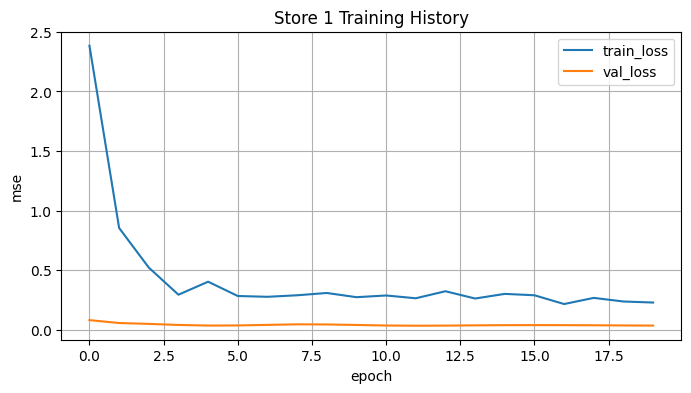

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step


Store 1 - MAE: 107882.86, RMSE: 132504.85
Saved predictions to: store_1_predictions.csv
Saved full model to store_1_model.h5


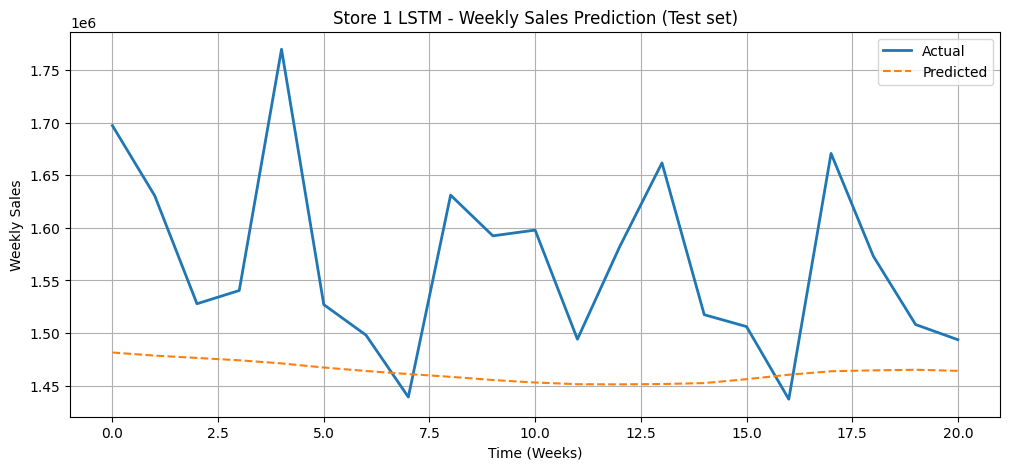

In [5]:
# ================================
# LSTM for Store-wise split (no scaling leakage) - run for Store 1 only
# ================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import tensorflow as tf

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Step 1: Load data
df = pd.read_csv("Walmart.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

# Step 2: Feature selection
features = ["Store", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
target = "Weekly_Sales"
seq_len = 10

# We'll prepare data store-wise and train/evaluate an LSTM only for store 1 to avoid cross-store leakage
store_id = 1  # change this to run other stores
store_df = df[df["Store"] == store_id].reset_index(drop=True)
n = len(store_df)
if n <= seq_len:
    raise ValueError(f"Not enough rows for store {store_id} to create sequences with seq_len={seq_len}")

# Raw feature and target arrays for this store (unscaled)
raw_X = store_df[features].values
raw_y = store_df[[target]].values

# Number of sequences (each sequence uses seq_len past rows to predict next row)
num_seq = n - seq_len
train_seq = int(0.7 * num_seq)
val_seq = int(0.15 * num_seq)
test_seq = num_seq - train_seq - val_seq

# Indices in the raw arrays to use for fitting scalers (fit only on training portion to avoid leakage)
# Training sequences use raw rows up to index (seq_len + train_seq - 1) in their windows, so include up to seq_len + train_seq
fit_end = seq_len + train_seq  # exclusive index for slicing

# Fit scalers on training portion only
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
scaler_X.fit(raw_X[:fit_end])
scaler_y.fit(raw_y[:fit_end])

# Scale full store data using scalers fitted on training data only
X_scaled = scaler_X.transform(raw_X)
y_scaled = scaler_y.transform(raw_y)

# Create sequences from scaled arrays
def create_sequences(X, y, seq_len=10):
    Xs, ys = [], []
    for i in range(seq_len, len(X)):
        Xs.append(X[i-seq_len:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Split sequences per-store into train/val/test (70/15/15)
X_train = X_seq[:train_seq]
y_train = y_seq[:train_seq]
X_val = X_seq[train_seq:train_seq+val_seq]
y_val = y_seq[train_seq:train_seq+val_seq]
X_test = X_seq[train_seq+val_seq:]
y_test = y_seq[train_seq+val_seq:]

print(f"Store {store_id}: total sequences={num_seq}, train={len(X_train)}, val={len(X_val)}, test={len(X_test)}")

# Step 3: Build an improved LSTM model for this store
n_features = X_train.shape[2]
# Defensive check: ensure there's at least one sample in each split
if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Training or test set is empty for this store - check seq_len and data length")

model = Sequential()
model.add(LSTM(128, return_sequences=True, input_shape=(seq_len, n_features)))
model.add(BatchNormalization())
model.add(Dropout(0.3))
model.add(LSTM(64))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

# Step 4: Prepare callbacks to stabilize training and save best model
checkpoint_path = f"best_model_store_{store_id}.weights.h5"
callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, save_weights_only=True, verbose=1)
]

# Step 5: Train model (use validation set to monitor)
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val), callbacks=callbacks, verbose=1)

# If checkpoint exists, load best weights saved during training
if os.path.exists(checkpoint_path):
    model.load_weights(checkpoint_path)
    print(f"Loaded best weights from {checkpoint_path}")
else:
    print("No checkpoint file found, using current model weights")

# Plot training history
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('epoch')
plt.ylabel('mse')
plt.legend()
plt.title(f'Store {store_id} Training History')
plt.grid(True)
plt.show()

# Step 6: Predict on test set and invert scaling
y_pred = model.predict(X_test)
y_pred_inv = scaler_y.inverse_transform(y_pred)
y_test_inv = scaler_y.inverse_transform(y_test)

# Step 7: Evaluation - MAE and RMSE (on original scale)
mae = mean_absolute_error(y_test_inv, y_pred_inv)
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
print(f"Store {store_id} - MAE: {mae:.2f}, RMSE: {rmse:.2f}")

# Save predictions and metrics for inspection
out_df = pd.DataFrame({"y_test": y_test_inv.flatten(), "y_pred": y_pred_inv.flatten()})
out_csv = f"store_{store_id}_predictions.csv"
out_df.to_csv(out_csv, index=False)
print("Saved predictions to:", out_csv)

# Save final model (architecture + weights) for reproducibility
final_model_path = f"store_{store_id}_model.h5"
try:
    model.save(final_model_path)
    print(f"Saved full model to {final_model_path}")
except Exception as e:
    print("Could not save full model (h5). You can save weights separately:", e)

# Step 8: Plot predictions vs actual (first 200 points or less)
n_plot = min(200, len(y_test_inv))
plt.figure(figsize=(12,5))
plt.plot(y_test_inv[:n_plot].flatten(), label="Actual", linewidth=2)
plt.plot(y_pred_inv[:n_plot].flatten(), label="Predicted", linestyle='dashed')
plt.title(f"Store {store_id} LSTM - Weekly Sales Prediction (Test set)")
plt.xlabel("Time (Weeks)")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()
